**Equilibrium Reactor: Water-Gas Shift**

In this tutorial we shift carbon monoxide to hydrogen with steam in an equilibrium reactor, and validate the result against an equivalent DWSIM Equilibrium Reactor model (Peng-Robinson property package).

Unlike a conversion reactor, where the user specifies how far the reaction goes, an equilibrium reactor calculates the extent of reaction from the **chemical equilibrium constant** at the reactor temperature.

### Reaction:

$$\mathrm{CO + H_2O \rightleftharpoons CO_2 + H_2} \qquad \Delta H_r(25\,^{\circ}\mathrm{C}) = -41.2\ \mathrm{kJ/mol}, \quad \Delta G_r(25\,^{\circ}\mathrm{C}) = -28.6\ \mathrm{kJ/mol}$$

* **Base component**: carbon monoxide
* **Reaction phase**: vapor
* **Reactor temperature**: 700 K (a typical high-temperature shift), no pressure drop

### Inlet Specifications:

| Stream | Composition (mol) | Mass Flow | Temperature | Pressure | Property package |
|---|---|---|---|---|---|
| Steam | 100 % water | 5 kg/s | 500 K | 1.01325 bar | IAPWS-95 steam tables |
| Hydrogen | 100 % hydrogen | 0.5 kg/s | 300 K | 1.01325 bar | Peng-Robinson (`syngas.py`) |
| Flue gas | 50 % CO, 50 % CO₂ | 1 kg/s | 300 K | 1.01325 bar | Peng-Robinson (`syngas.py`) |

---

> **Translator: moving a stream between property packages**
>
> The steam is described with the steam tables, while the mixer and reactor use the Peng-Robinson syngas package. A `Translator` block hands the steam over: it sets the outlet flow, temperature, pressure and composition equal to the inlet. It does **not** copy enthalpy, because each property package measures enthalpy from a different reference state (the steam tables from liquid water at the triple point, `syngas.py` from the elements at 25 °C). Mixing streams with different enthalpy references directly creates energy out of nothing; in an earlier version of the DWSIM model this heated the mixer outlet to 1028 K instead of about 355 K. DWSIM has no translator unit, so in DWSIM the steam stream is simply defined on the Peng-Robinson package at the same temperature and pressure.

> **Equilibrium constant**
>
> `wgs_reaction.py` calculates the equilibrium constant from the standard Gibbs energy of reaction at the reactor temperature,
> $\ln K(T) = -\sum_j \nu_j \left(h_j(T) - T\,s_j(T)\right) / RT$,
> using the ideal gas enthalpies and entropies of the property package. This keeps the temperature dependence of the heat of reaction, like DWSIM's Gibbs energy based constant (K ≈ 9.4 at 700 K). The reaction has equal moles on both sides, so K is the same on a mole fraction or partial pressure basis.

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


## Setting up and solving the flowsheet

The flowsheet is steam Feed → Translator, plus hydrogen and flue gas Feeds → Mixer → EquilibriumReactor → syngas Product, built in `equilibrium_reactor.py`. The reactor outlet temperature is fixed at 700 K and the reactor calculates the heat duty needed to hold it. DWSIM's residue (liquid) outlet is empty, so the IDAES model has a single vapor outlet.

In [2]:
from equilibrium_reactor import setup_equilibrium_reactor_model, report_equilibrium_reactor_properties

# Create and solve the model
model, results = setup_equilibrium_reactor_model(
    steam={"flow_mass": 5.0, "temperature": 500, "pressure": 101325},  # kg/s, K, Pa
    hydrogen={"flow_mass": 0.5, "temperature": 300, "pressure": 101325, "mole_frac": {"hydrogen": 1.0}},
    flue_gas={"flow_mass": 1.0, "temperature": 300, "pressure": 101325,
              "mole_frac": {"carbon_monoxide": 0.5, "carbon_dioxide": 0.5}},
    reactor_temperature=700,  # K
)
print(results.solver.termination_condition)

prop = report_equilibrium_reactor_properties(model)

The initial DOF is 18
The final DOF is 0
optimal

Unit : fs.steam                                                            Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                         Units          Outlet  
    Molar Flow          mole / second     277.54
    Mass Flow       kilogram / second     5.0000
    T                          kelvin     500.00
    P                          pascal 1.0132e+05
    Vapor Fraction      dimensionless     1.0000
    Molar Enthalpy       joule / mole     52758.

Unit : fs.hydrogen                                                         Time: 0.0
------------------------------------------------------------------------------------
    Stream Table
                                            Units        Outlet  
    Total Molar Flowrate                 mole / second     248.03
    Total Mole Fraction carbon_monoxide  dimensionless 1.0000e-10
    Total Mole Fraction water     

In [3]:
from pyomo.environ import value

k_eq = value(model.fs.reactor.control_volume.reactions[0].k_eq["water_gas_shift"])
print("Equilibrium constant at 700 K: {0:.3f}".format(k_eq))

Equilibrium constant at 700 K: 9.394


In [4]:
# Visualize (if needed)
model.fs.visualize("Equilibrium Reactor Model")

'idaes.co re.util.diagnostics_tools.diagnostics_toolbox.DiagnosticsToolbox'.
Please update your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
'idaes.core.util.diagnostics_tools.diagnostics_toolbox.CONFIG'. Please update
your import.  (deprecated in 2.12.0) (called from <frozen
importlib._bootstrap>:488)
2026-11-01 13:23:52 [INFO] idaes.idaes_ui.fv.fsvis: Started visualization server
2026-11-01 13:23:52 [INFO] idaes.idaes_ui.fv.fsvis: Saving flowsheet to default file 'Equilibrium Reactor Model.json' in current directory (c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\Equilibrium Reactor)
2026-11-01 13:23:53 [WARNING] idaes.idaes_ui.fv.fsvis: Flowsheet name changed: old='Equilibrium Reactor Model' new='Equilibrium-Reactor-Model'
Flowsheet name changed to 'Equilibrium-Reactor-Model'
2026-11-01 13:23:53 [INFO] idaes.idaes_ui.fv.fsvis: Flowsheet visualization at: http://localhost:58807/app?id=Equilibrium-Reactor-Model


VisualizeResult(store=<idaes_ui.fv.persist.FileDataStore object at 0x000001FE8756FE60>, port=58807, server=<idaes_ui.fv.model_server.FlowsheetServer object at 0x000001FEC9457740>, save_diagram=<bound method SaveDiagramScreenshot.save_diagram_screenshot of <idaes_ui.fv.save_diagram_screenshot.SaveDiagramScreenshot object at 0x000001FEC9095D00>>)

## DWSIM model

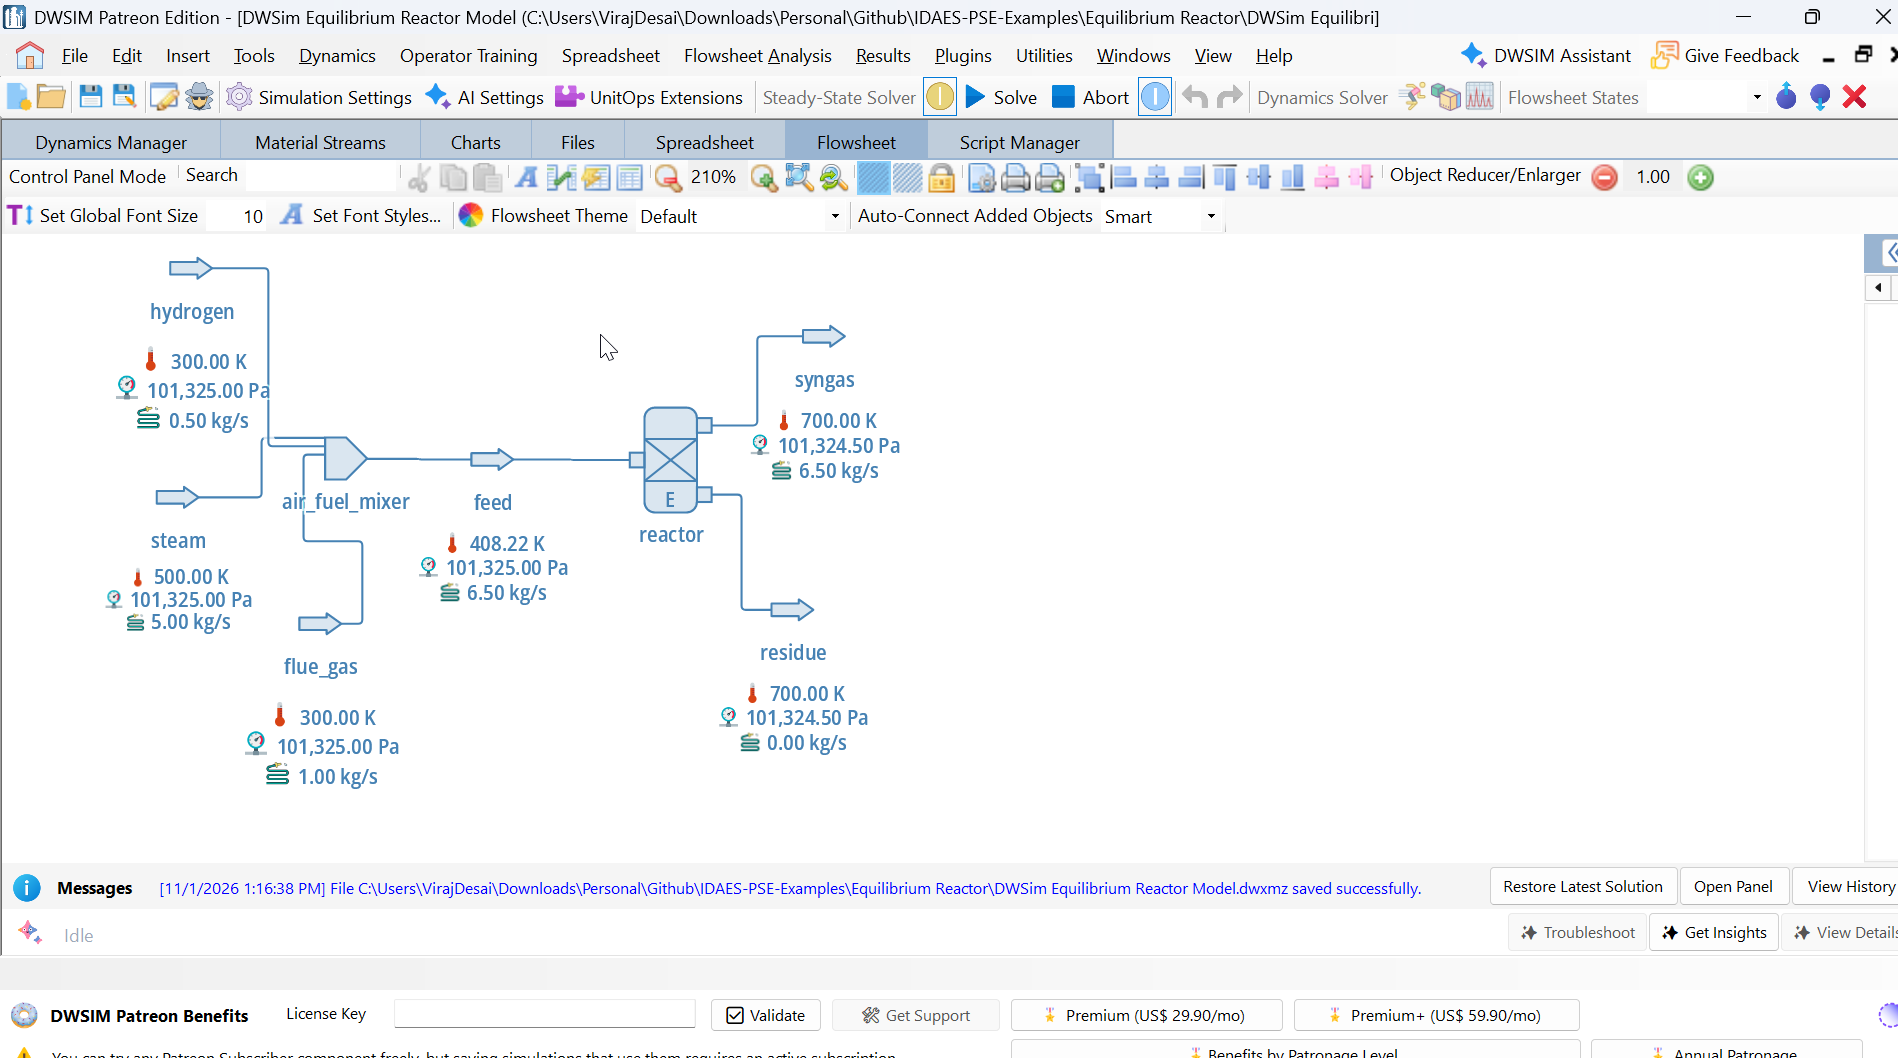

In [5]:
from IPython.display import Image
Image(filename="DWSim Equilibrium Reactor.png")

In [6]:
import webbrowser
import tempfile
import os

def display_image_in_browser(image_path, title="Image Viewer"):
    # Create a temporary HTML file that embeds the image
    html_content = f"""
    <html>
        <head>
            <title>{title}</title>
        </head>
        <body style="text-align: center;">
            <h2>{title}</h2>
            <img src="file://{os.path.abspath(image_path)}" style="max-width:90%; max-height:90%;">
        </body>
    </html>
    """
    with tempfile.NamedTemporaryFile('w', delete=False, suffix='.html') as f:
        f.write(html_content)
        temp_html_path = f.name

    webbrowser.open(f'file://{temp_html_path}')


In [7]:
display_image_in_browser("DWSim Equilibrium Reactor.png", title="DWSim Equilibrium Reactor Model Check")

## Validation against DWSIM

The DWSIM results are read directly from the solved `.dwxmz` file and compared with IDAES. The equilibrium composition depends on the equilibrium constant, so small differences come from the ideal gas heat capacity and formation data (CoolProp fit in IDAES vs DWSIM's ChemSep database).

In [ ]:
from equilibrium_reactor import read_dwsim_results, compare_with_dwsim

dwsim = read_dwsim_results("DWSim Equilibrium Reactor Model.dwxmz")
compare_with_dwsim(model, dwsim)

,IDAES,DWSIM,Difference,Error (%)
Mixed feed temperature (K),408.226881,408.215408,1.147292e-02,2.810507e-03
Reactor temperature (K),700.000000,700.000000,0.000000e+00,0.000000e+00
Reactor heat duty (kW),4909.940102,4912.349505,-2.409403e+00,-4.904787e-02
Syngas molar flow (mol/s),553.343030,553.343030,1.632261e-07,2.949818e-08
Syngas carbon_monoxide (mol/s),2.608453,2.611124,-2.670993e-03,-1.022928e-01
Syngas water (mol/s),266.265519,266.268190,-2.671018e-03,-1.003131e-03
Syngas carbon_dioxide (mol/s),25.161765,25.159094,2.671098e-03,1.061683e-02
Syngas hydrogen (mol/s),259.307293,259.304622,2.671076e-03,1.030092e-03
CO conversion,0.812140,0.811948,1.923645e-04,2.369174e-02


----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 64319)
Traceback (most recent call last):
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\socketserver.py", line 318, in _handle_request_noblock
    self.process_request(request, client_address)
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\socketserver.py", line 349, in process_request
    self.finish_request(request, client_address)
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\socketserver.py", line 362, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "c:\Users\VirajDesai\Downloads\Personal\Github\IDAES-PSE-Examples\.venv\Lib\site-packages\idaes_ui\fv\model_server.py", line 257, in __init__
    super().__init__(*args, **kwargs)
  File "C:\Users\VirajDesai\AppData\Local\Programs\Python\Python312\Lib\http\server.py", line 672, in __init__
    super().__init__(*args, *